# Statistical and boosting research

**Question:** can an honest next-day national forecast improve on the supplied RTE proxy?

This notebook trains and tunes ARIMA, SARIMA, SARIMAX, histogram gradient boosting,
LightGBM, quantile LightGBM and a penalized additive spline GAM. Notebook 08 adds
six neural architectures and performs the frozen final comparison.

The experiment is retrospective: original demand/weather/RTE issue vintages and
hourly aggregation lineage are unverified. The 2025–26 period has already been
inspected. No operational superiority or euro savings can be claimed.

Running this notebook creates a **new versioned run**, rather than overwriting
the legacy results or changing raw CSVs. The default compact CPU budget evaluates
two configurations per family on four full chronological validation quarters.
It is a bounded research comparison, not exhaustive optimization.

In [1]:
import os, sys, json
from pathlib import Path
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
ROOT = Path.cwd()
if not (ROOT / "config/research_experiment.json").exists():
    ROOT = ROOT.parent
assert (ROOT / "config/research_experiment.json").exists(), "Run from project/notebooks"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.common import plotting_style
from src.research_experiment import ResearchRun, POINT_FAMILIES, NEURAL_FAMILIES
plotting_style()

## 1. Freeze the forecast contract before fitting

Origin is 11:00 Europe/Paris on day D. Predict every actual interval of local D+1,
including 23/24/25-hour DST days. Demand becomes available at interval end plus
two hours **by assumption**, strictly before the cutoff. Tomorrow-temperature is
excluded. Supplied RTE is a retrospective benchmark, never verified issue-time data.

`compact` runs actual training, tuning and daily replay. Change budgets only in a
new run before examining its final comparison. The shared functions are in
`src/research_data.py`, `research_models.py`, and `research_experiment.py`.

In [2]:
PROFILE = "compact"
RESUME_LATEST = os.environ.get("RESEARCH_RESUME_RUN", "0") == "1"
run = ResearchRun.latest(ROOT) if RESUME_LATEST else ResearchRun.create(ROOT, profile=PROFILE)
data = run.data
print("Research output directory:", run.path)
display(pd.Series(run.contract, name="frozen research assumptions"))

Research output directory: /Users/alivakof/Desktop/Time Series/Project/reports/research_v2/20261020T164443776583Z


version                                                                 research-v2.0
status                                             retrospective_assumed_availability
timezone                                                                 Europe/Paris
origin_hour_local                                                                  11
origin_minute_local                                                                 0
interval_duration_hours                                                             1
demand_publication_delay_hours                                                      2
maximum_feature_lookback_days                                                      35
minimum_training_days                                                             270
minimum_training_note               New experiment: nine-month minimum replaces le...
matched_history_start                                                      2023-01-02
bias_window_days                                      

## 2. Audit eligibility and compare both datasets fairly

The main national and regional-assisted arms use the same 2023 onward history.
National demand remains the target; regional sums do not replace it. Missing
evaluation targets remain missing. Peaks remain in the data.

Tabular regional assistance adds pre-cutoff regional histories and temperatures.
No regional RTE forecast exists in the supplied dataset.

In [3]:
from src.research_data import data_summary, latest_eligible_time
display(data_summary(data))
display(pd.DataFrame({"feature_group": ["national", "regional-assisted"],
                      "feature_count": [len(data.columns("national")), len(data.columns("regional"))]}))
assert data.labels.actual_mw.isna().sum() == data.national.load_mw.isna().sum()
assert not set(data.columns("regional")) & {"actual_mw", "realized_temperature_c", "oracle_temperature_c"}
data_summary(data).to_csv(run.path / "tables/data_audit.csv", index=False)
display(data.features[["origin", "delivery_time", "max_history_available_at"]].head())

,dataset,rows,series,missing_targets,start_utc,end_utc
0,national,30623,1,3,2023-01-01 23:00:00+00:00,2026-06-30 21:00:00+00:00
1,regional,367476,12,36,2023-01-01 23:00:00+00:00,2026-06-30 21:00:00+00:00


,feature_group,feature_count
0,national,24
1,regional-assisted,72


,origin,delivery_time,max_history_available_at
0,2023-02-05 10:00:00+00:00,2023-02-05 23:00:00+00:00,2023-02-05 09:00:00+00:00
1,2023-02-05 10:00:00+00:00,2023-02-06 00:00:00+00:00,2023-02-05 09:00:00+00:00
2,2023-02-05 10:00:00+00:00,2023-02-06 01:00:00+00:00,2023-02-05 09:00:00+00:00
3,2023-02-05 10:00:00+00:00,2023-02-06 02:00:00+00:00,2023-02-05 09:00:00+00:00
4,2023-02-05 10:00:00+00:00,2023-02-06 03:00:00+00:00,2023-02-05 09:00:00+00:00


## 3. Use chronological folds, then calibration, then comparison

Four 2024 quarters are the outer validation folds. Each contains daily forecast
origins; every fit additionally filters label publication timestamps. The first
fold has approximately 328 usable supervised days after feature warm-up, so the
new contract explicitly replaces the legacy one-year guard with nine months.

Calibration deliveries: 2 January–29 June 2025. June 30 is a boundary buffer:
its evening outcomes are unavailable at the first July 1 forecast origin.
Final historical comparison: July 2025–June 2026. End dates below are exclusive.
No shuffled cross-validation is used.

,stage,start,end
0,2024_Q1,2024-01-01,2024-04-01
1,2024_Q2,2024-04-01,2024-07-01
2,2024_Q3,2024-07-01,2024-10-01
3,2024_Q4,2024-10-01,2025-01-01
4,calibration,2025-01-02,2025-06-30
5,test,2025-07-01,2026-07-01


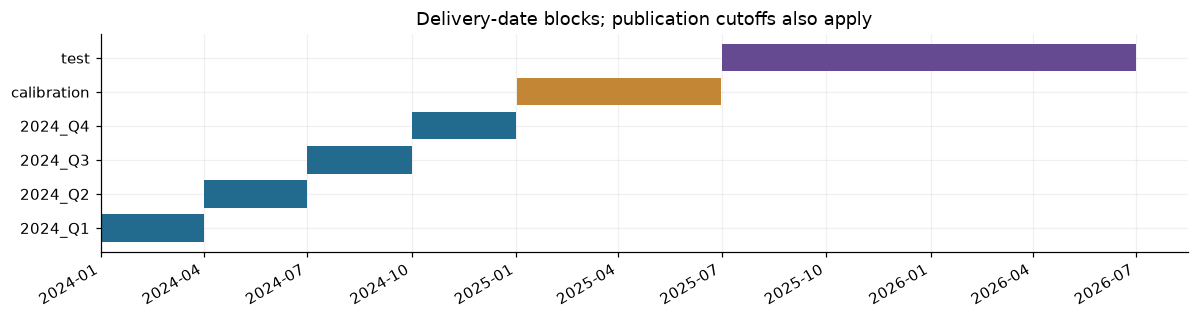

In [4]:
split_rows = [dict(stage=f["name"], start=f["start"], end=f["end"]) for f in run.contract["validation_folds"]]
split_rows += [dict(stage=k, start=run.contract[k]["start"], end=run.contract[k]["end"]) for k in ("calibration", "test")]
splits = pd.DataFrame(split_rows)
display(splits)
fig, ax = plt.subplots(figsize=(11, 3))
for i, row in splits.iterrows():
    start, end = pd.Timestamp(row.start), pd.Timestamp(row.end)
    ax.barh(i, (end-start).days, left=start, color=("#236b8e" if i<4 else "#c28635" if i==4 else "#654a91"))
ax.set_yticks(range(len(splits)), splits.stage)
ax.xaxis_date(); ax.set_title("Delivery-date blocks; publication cutoffs also apply")
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## 4. Inspect the statistical and tabular candidates

ARIMA/SARIMA/SARIMAX use genuine statsmodels implementations. Compact statistical
fits use explicitly recent 56/84-day windows, small daily seasonal orders and
bounded optimizer iterations; convergence is recorded, not assumed.

The separate gradient-boosting model is sklearn histogram boosting. LightGBM is
another implementation. Quantile LightGBM's median is scored as its point
forecast; its 5th/95th quantiles are fitted only after parameter selection.

The GAM is independent penalized B-splines plus Ridge, explicitly **not pyGAM**.
Its smoothing is selected on the same chronological folds. Model objectives
(mean, median or quantile) are recorded rather than treated as interchangeable.

In [5]:
from src.research_models import MODEL_REGISTRY, parameter_grid
display(pd.DataFrame(MODEL_REGISTRY).T)
candidate_parameters = {family: parameter_grid(family, "fast") for family in POINT_FAMILIES}
display(pd.DataFrame([{"family": family, "trial": i, "parameters": params}
                      for family, candidates in candidate_parameters.items() for i, params in enumerate(candidates)]))

,kind,hypothesis,objective,uses_exog,implementation
arima,statistical,A small nonseasonal autoregressive model is a ...,Gaussian likelihood; conditional mean,False,NaN
sarima,statistical,Explicit daily seasonality improves on nonseas...,Gaussian likelihood; conditional mean,False,NaN
sarimax,statistical,Available calendar and historical regressors i...,Gaussian likelihood; conditional mean,True,NaN
hist_gradient_boosting,tabular,Regularized nonlinear interactions improve on ...,absolute error; conditional median,True,NaN
lightgbm,tabular,Leaf-wise boosting improves accuracy or effici...,absolute error; conditional median,True,NaN
lightgbm_quantile,tabular,Conditional quantiles describe asymmetric dema...,pinball loss at the declared quantile,True,NaN
gam,tabular,Penalized additive smooth effects can compete ...,penalized squared error; conditional mean,True,sklearn independent B-splines + Ridge; not pyGAM


,family,trial,parameters
0,arima,0,"{'order': [2, 1, 0], 'maxiter': 40, 'window_da..."
1,arima,1,"{'order': [3, 1, 1], 'maxiter': 60, 'window_da..."
2,sarima,0,"{'order': [1, 0, 0], 'seasonal_order': [1, 0, ..."
3,sarima,1,"{'order': [2, 0, 0], 'seasonal_order': [0, 0, ..."
4,sarimax,0,"{'order': [1, 0, 0], 'seasonal_order': [1, 0, ..."
5,sarimax,1,"{'order': [2, 0, 0], 'seasonal_order': [0, 0, ..."
6,hist_gradient_boosting,0,"{'max_iter': 80, 'max_leaf_nodes': 15, 'min_sa..."
7,hist_gradient_boosting,1,"{'max_iter': 120, 'max_leaf_nodes': 31, 'min_s..."
8,lightgbm,0,"{'n_estimators': 100, 'num_leaves': 15, 'min_c..."
9,lightgbm,1,"{'n_estimators': 150, 'num_leaves': 31, 'min_c..."


## 5. Train, validate and tune the statistical models

Each daily forecast starts from the latest released observation. The unobserved
remainder of day D is forecast before tomorrow's intervals are selected.
SARIMAX uses known future calendar regressors covering the entire bridge.
Between monthly parameter fits, statistical states consume only newly released
observations. A failed fit is logged and falls back until the next scheduled fit.

In [6]:
statistical_trials = run.tune(["arima", "sarima", "sarimax"])
display(statistical_trials.tail(12))

REPLAY arima__national 2024_Q1_trial0 2024-01-01..2024-04-01 config=dcf3456784a9


REPLAY arima__national 2024_Q2_trial0 2024-04-01..2024-07-01 config=7819bfc56ce8


REPLAY arima__national 2024_Q3_trial0 2024-07-01..2024-10-01 config=1c08d8f1aefa


REPLAY arima__national 2024_Q4_trial0 2024-10-01..2025-01-01 config=d3b977f2d82c


REPLAY arima__national 2024_Q1_trial1 2024-01-01..2024-04-01 config=39e8802bff64


...

REPLAY sarimax__national 2024_Q2_trial1 2024-04-01..2024-07-01 config=61f61effa880


REPLAY sarimax__national 2024_Q3_trial1 2024-07-01..2024-10-01 config=de39b9e929eb


REPLAY sarimax__national 2024_Q4_trial1 2024-10-01..2025-01-01 config=4d9f5a877188


SELECTED sarimax__national: {"MAE_MW": 3180.947270027331, "arm": "national", "family": "sarimax", "params": {"factr": 100000000.0, "maxiter": 40, "order": [1, 0, 0], "pgtol": 0.001, "seasonal_order": [1, 0, 0, 24], "window_days": 56}, "raw_availability": 1.0, "status": "selected", "trial": 0}


,model,family,arm,trial,fold,params_json,eligible_targets,scored,missing_targets,availability,MAE_MW,RMSE_MW,bias_actual_minus_forecast_MW,WAPE_percent,raw_availability,raw_MAE_MW,fallback_fraction
58,patchtst__national,patchtst,national,1,2024_Q4,"{""h"": 48, ""input_size"": 336, ""learning_rate"": ...",2208,2208,1,1.0,6113.121984,7858.715119,2616.302973,11.278359,1.0,6113.121984,0.0
59,gru__national,gru,national,1,2024_Q2,"{""h"": 48, ""input_size"": 336, ""learning_rate"": ...",2184,2184,0,1.0,4974.542243,5967.397354,-1080.299451,11.126504,1.0,4974.542243,0.0
60,nhits__regional,nhits,regional,0,2024_Q1,"{""h"": 48, ""input_size"": 168, ""learning_rate"": ...",2183,2183,0,1.0,5192.011631,6602.807687,204.922179,8.852633,1.0,5192.011631,0.0
61,sarimax__national,sarimax,national,1,2024_Q3,"{""factr"": 100000000.0, ""maxiter"": 60, ""order"":...",2208,2208,0,1.0,2496.712977,3204.835524,575.358097,5.822199,1.0,2496.712977,0.0
62,patchtst__regional,patchtst,regional,0,2024_Q1,"{""h"": 48, ""input_size"": 168, ""learning_rate"": ...",2183,2183,0,1.0,4899.308905,6300.458455,-111.037168,8.353561,1.0,4899.308905,0.0
63,gru__national,gru,national,1,2024_Q3,"{""h"": 48, ""input_size"": 336, ""learning_rate"": ...",2208,2208,0,1.0,4775.085669,5617.008595,-336.869792,11.135240,1.0,4775.085669,0.0
64,nhits__regional,nhits,regional,0,2024_Q2,"{""h"": 48, ""input_size"": 168, ""learning_rate"": ...",2184,2184,0,1.0,5423.123894,6772.131517,2211.084361,12.129842,1.0,5423.123894,0.0
65,patchtst__regional,patchtst,regional,0,2024_Q2,"{""h"": 48, ""input_size"": 168, ""learning_rate"": ...",2184,2184,0,1.0,4399.501234,5511.003421,641.207704,9.840316,1.0,4399.501234,0.0
66,nhits__regional,nhits,regional,0,2024_Q3,"{""h"": 48, ""input_size"": 168, ""learning_rate"": ...",2208,2208,0,1.0,6026.184961,7416.999053,4362.877300,14.052735,1.0,6026.184961,0.0
67,patchtst__regional,patchtst,regional,0,2024_Q3,"{""h"": 48, ""input_size"": 168, ""learning_rate"": ...",2208,2208,0,1.0,4873.605559,6012.062733,2318.565890,11.364983,1.0,4873.605559,0.0


## 6. Train and tune boosting, quantile boosting and GAM

Both national-only and regional-assisted arms use identical delivery dates.
Imputation, spline construction and any scaling are fitted on each training slice.
Automatic random early stopping is disabled for tabular models; the external
chronological search selects capacity and iteration count.

In [7]:
tabular_trials = run.tune(["hist_gradient_boosting", "lightgbm", "lightgbm_quantile", "gam"])
selected_point = json.loads((run.path / "selected_parameters.json").read_text())
display(pd.DataFrame(selected_point).T)

REPLAY hist_gradient_boosting__national 2024_Q1_trial0 2024-01-01..2024-04-01 config=464268f0b3e4


REPLAY hist_gradient_boosting__national 2024_Q2_trial0 2024-04-01..2024-07-01 config=3aceed73282f


REPLAY hist_gradient_boosting__national 2024_Q3_trial0 2024-07-01..2024-10-01 config=c29a42840230


REPLAY hist_gradient_boosting__national 2024_Q4_trial0 2024-10-01..2025-01-01 config=84609e9aa3b4


REPLAY hist_gradient_boosting__national 2024_Q1_trial1 2024-01-01..2024-04-01 config=7070d6097b8f


...

REPLAY gam__regional 2024_Q2_trial1 2024-04-01..2024-07-01 config=117aa26cd896


REPLAY gam__regional 2024_Q3_trial1 2024-07-01..2024-10-01 config=e52608fd54d1


REPLAY gam__regional 2024_Q4_trial1 2024-10-01..2025-01-01 config=8af690fab446


SELECTED gam__regional: {"MAE_MW": 2191.2127636044834, "arm": "regional", "family": "gam", "params": {"alpha": 100.0, "degree": 3, "n_knots": 6}, "raw_availability": 1.0, "status": "selected", "trial": 1}


,family,arm,status,trial,params,MAE_MW,raw_availability
arima__national,arima,national,selected,0,"{'order': [2, 1, 0], 'maxiter': 40, 'window_da...",5664.058858,1.0
nbeats__national,nbeats,national,selected,0,"{'h': 48, 'input_size': 168, 'max_steps': 20, ...",5706.522281,1.0
sarima__national,sarima,national,selected,0,"{'order': [1, 0, 0], 'seasonal_order': [1, 0, ...",3512.540458,1.0
nbeats__regional,nbeats,regional,selected,0,"{'h': 48, 'input_size': 168, 'max_steps': 20, ...",5669.09407,1.0
nhits__national,nhits,national,selected,0,"{'h': 48, 'input_size': 168, 'max_steps': 20, ...",5586.086011,1.0
patchtst__national,patchtst,national,selected,0,"{'h': 48, 'input_size': 168, 'max_steps': 20, ...",5803.461473,1.0
gru__national,gru,national,selected,0,"{'h': 48, 'input_size': 168, 'max_steps': 20, ...",5347.148367,1.0
sarimax__national,sarimax,national,selected,0,"{'order': [1, 0, 0], 'seasonal_order': [1, 0, ...",3180.94727,1.0
hist_gradient_boosting__national,hist_gradient_boosting,national,selected,1,"{'max_iter': 120, 'max_leaf_nodes': 31, 'min_s...",2192.268802,1.0
hist_gradient_boosting__regional,hist_gradient_boosting,regional,selected,1,"{'max_iter': 120, 'max_leaf_nodes': 31, 'min_s...",2075.784054,1.0


## 7. Diagnose stability, overfit and underfit before touching final outcomes

Compare all fold scores, raw availability and fallback fractions. A large
training–validation gap can suggest overfitting; poor performance in both can
also reflect poor inputs or distribution changes. Fold variation is not a formal
bias–variance decomposition. Optimizer nonconvergence is reported separately.

The final comparison is deliberately deferred until notebook 08 has finished
neural-model validation and all policies are frozen.

,model,trial,MAE_MW,fold_std_MW,raw_availability,fallback_fraction
2,gam__national,0,2067.660492,872.423757,1.0,0.0
9,hist_gradient_boosting__regional,1,2077.480093,879.746578,1.0,0.0
17,lightgbm_quantile__regional,1,2079.342328,887.924779,1.0,0.0
13,lightgbm__regional,1,2086.055904,879.777182,1.0,0.0
15,lightgbm_quantile__national,1,2148.984533,1053.348048,1.0,0.0
16,lightgbm_quantile__regional,0,2168.935570,942.344980,1.0,0.0
11,lightgbm__national,1,2174.747694,1000.069004,1.0,0.0
12,lightgbm__regional,0,2180.850297,955.196333,1.0,0.0
3,gam__national,1,2186.841841,946.682396,1.0,0.0
5,gam__regional,1,2193.299532,815.383438,1.0,0.0


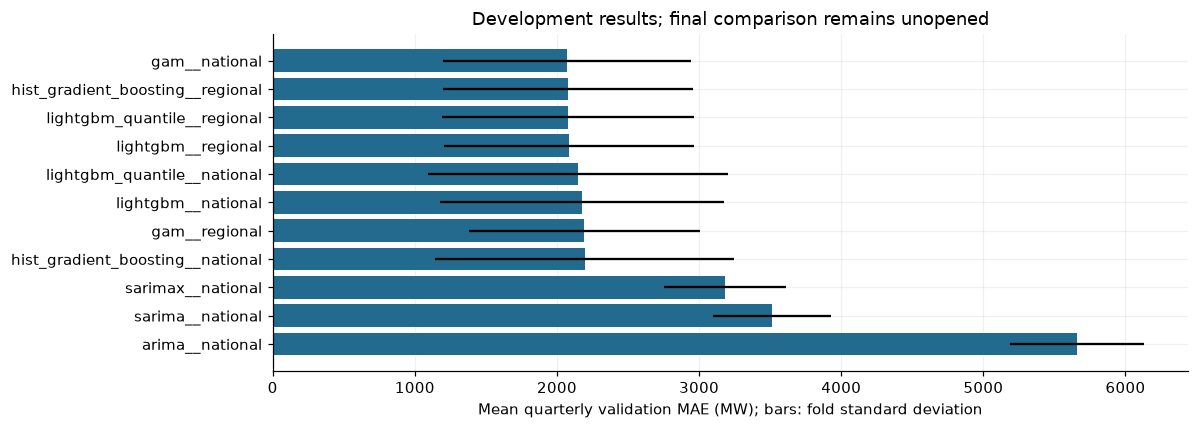

,fits,failures,total_fit_seconds
model,,,
arima__national,32,0,10.453607
gam__national,32,0,26.639119
gam__regional,32,0,103.461654
gru__national,32,0,236.581092
gru__regional,8,0,182.383661
hist_gradient_boosting__national,32,0,150.313977
hist_gradient_boosting__regional,32,0,165.020897
lightgbm__national,32,0,44.640270
lightgbm__regional,32,0,227.394928


Continue with notebook 08 using this same versioned run: /Users/alivakof/Desktop/Time Series/Project/reports/research_v2/20261020T164443776583Z


In [8]:
trials = pd.read_csv(run.path / "tables/tuning_trials.csv")
trials = trials.loc[trials.family.isin(POINT_FAMILIES)]
summary = trials.groupby(["model", "trial"]).agg(MAE_MW=("MAE_MW", "mean"),
           fold_std_MW=("MAE_MW", "std"), raw_availability=("raw_availability", "mean"),
           fallback_fraction=("fallback_fraction", "mean")).reset_index()
display(summary.sort_values("MAE_MW"))
best = summary.loc[summary.groupby("model").MAE_MW.idxmin()].sort_values("MAE_MW")
fig, ax = plt.subplots(figsize=(11, 4))
ax.barh(best.model, best.MAE_MW, xerr=best.fold_std_MW.fillna(0), color="#236b8e")
ax.invert_yaxis(); ax.set_xlabel("Mean quarterly validation MAE (MW); bars: fold standard deviation")
ax.set_title("Development results; final comparison remains unopened")
plt.tight_layout(); fig.savefig(run.path / "figures/point_validation.png", bbox_inches="tight"); plt.show()
fit_records = [r for p in (run.path / "fits").glob("*.json") for r in json.loads(p.read_text())]
fit_diagnostics = pd.DataFrame([{**{k: v for k, v in r.items() if k not in ("metadata", "params", "traceback")},
                               "converged": (r.get("metadata") or {}).get("converged")} for r in fit_records])
display(fit_diagnostics.groupby("model").agg(fits=("status", "size"), failures=("status", lambda s: s.ne("fit").sum()),
             total_fit_seconds=("elapsed_seconds", "sum")))
fit_diagnostics.to_csv(run.path / "tables/point_fit_diagnostics.csv", index=False)
print("Continue with notebook 08 using this same versioned run:", run.path)

## RTE-assisted extension: direct prediction versus residual correction

This separate experiment preserves the preceding independent-model results. Four tabular families—histogram gradient boosting, LightGBM, quantile LightGBM and penalized GAM—receive `rte_at_origin_mw` and `rte_bias_recent_mw`, with national and regional feature arms. Each has a direct demand target and an RTE-error target. Both use identical predictors and fallback rules.

Two configurations per variant are evaluated across all four 2024 chronological quarters. The extension therefore has16 variants and128 configuration-quarter validations. Preprocessing is fitted inside each historical fit. The origin remains11:00 Europe/Paris; only labels released strictly before that origin can enter training. No realized future weather enters predictors. Supplied RTE is an assumed-available retrospective proxy, not a verified forecast vintage.

The best assisted variant and complete policy are frozen using development data before new calibration/test replay. The previously inspected test remains retrospective. Raw RTE and simple28-day RTE bias correction are both required references; beating raw RTE alone does not show incremental value beyond simple correction.

In [2]:
from src.rte_assisted import RTEAssistedRun
assisted_run = RTEAssistedRun.latest(ROOT)
display(Markdown(f"**RTE extension run:** `{assisted_run.path}`"))
display(pd.DataFrame([
    {"mode": "direct", "predictors": "calendar/history/past weather + RTE + recent RTE bias", "target": "actual demand", "forecast": "model output"},
    {"mode": "residual", "predictors": "same predictors", "target": "actual demand minus RTE", "forecast": "RTE + predicted residual"},
]))
display(pd.DataFrame({"arm": ["national", "regional"],
    "predictor_count": [len(assisted_run.data.columns(a, rte_assisted=True)) for a in ("national", "regional")]}))

**RTE extension run:** `/Users/alivakof/Desktop/Time Series/Project/reports/rte_assisted/20261020T203527821283Z`

,mode,predictors,target,forecast
0,direct,calendar/history/past weather + RTE + recent R...,actual demand,model output
1,residual,same predictors,actual demand minus RTE,RTE + predicted residual


,arm,predictor_count
0,national,26
1,regional,74


### Tune chronologically and freeze the extension

The same bounded parameter grids used for independent tabular models are retuned for each RTE-assisted target/arm. Every configuration receives all daily origins within every development quarter. Forecasts are recorded before evaluation outcomes are joined. Search logs, per-fit predictor columns and chronological availability checks remain in the versioned run directory. Cached completed folds are reused only when their hashes and origin ledgers match.

In [3]:
import contextlib
with (assisted_run.path / "development_execution.log").open("a") as assisted_log:
    with contextlib.redirect_stdout(assisted_log):
        assisted_trials = assisted_run.tune_assisted()
assisted_freeze = assisted_run.freeze_assisted()
assisted_development = pd.DataFrame([
    {"model": key, "family": value["family"], "arm": value["arm"], "mode": value["mode"],
     "development_MAE_MW": value["MAE_MW"], "configuration": value["trial"],
     "raw_availability": value["raw_availability"]}
    for key, value in assisted_freeze["selections"].items()
]).sort_values("development_MAE_MW")
display(assisted_development)
display(Markdown(f"**Development-selected assisted model:** `{assisted_freeze['selected_assisted_model']}`\n\n"
    f"**Development-selected complete policy:** `{assisted_freeze['selected_complete_policy']}`\n\n"
    f"**Completed configuration-quarter validations:** {len(assisted_trials)}/128. Continue in notebook08's RTE-assisted extension."))

,model,family,arm,mode,development_MAE_MW,configuration,raw_availability
11,lightgbm_quantile__regional__rte_residual,lightgbm_quantile,regional,residual,822.126215,1,0.999886
7,lightgbm__regional__rte_residual,lightgbm,regional,residual,827.538493,1,0.999886
3,hist_gradient_boosting__regional__rte_residual,hist_gradient_boosting,regional,residual,828.641682,1,0.999886
5,lightgbm__national__rte_residual,lightgbm,national,residual,854.456758,0,0.999886
1,hist_gradient_boosting__national__rte_residual,hist_gradient_boosting,national,residual,860.384151,0,0.999886
9,lightgbm_quantile__national__rte_residual,lightgbm_quantile,national,residual,862.181512,0,0.999886
6,lightgbm__regional__rte_direct,lightgbm,regional,direct,872.646761,1,0.999886
2,hist_gradient_boosting__regional__rte_direct,hist_gradient_boosting,regional,direct,880.551552,1,0.999886
10,lightgbm_quantile__regional__rte_direct,lightgbm_quantile,regional,direct,883.964675,1,0.999886
4,lightgbm__national__rte_direct,lightgbm,national,direct,898.558740,0,0.999886


**Development-selected assisted model:** `lightgbm_quantile__regional__rte_residual`

**Development-selected complete policy:** `lightgbm_quantile__regional__rte_residual`

**Completed configuration-quarter validations:** 128/128. Continue in notebook08's RTE-assisted extension.

## RTE D1, expanded features and cold-evening risk

This separately frozen research experiment uses `rte_forecast_d1_mw` as an assumed available input at 11:00 Europe/Paris on D, to forecast every actual hourly interval of D+1. Historical issue vintages remain unverified. No next-but-one-day product or 05:00 rule is used.

The target is national consumption in all three predictor arms: national history, regional history only, and both. Regional-only includes national RTE and known calendar, but excludes national demand/weather/error history. It does not substitute a regional sum for national truth.

The feature dictionary distinguishes origin-anchored AR lags, publication-gated target lags, moving averages of observations, rolling dispersion/ranges/counts, EWMAs, RTE error history and target-day RTE profile shape. ARIMA MA terms describe latent innovations and are not the same as rolling means. Future observed weather is excluded.

New learned predictors are ridge demand forecasts and probabilities of cold/large RTE underprediction. Each value was produced out of sample using an earlier monthly fit. All imputers/scalers use training rows only.

In [2]:
from src.rte_risk_lab import RiskLabRun
risk_run = RiskLabRun.latest(ROOT)
risk_run.verify_manifest()
risk_features = risk_run.frame
display(Markdown(f"**Frozen feature/risk run:** `{risk_run.path}`"))
feature_sizes = pd.DataFrame([
    {"predictor arm": arm, "basic columns": len(risk_run.data.columns(arm, tier="basic")),
     "engineered columns": len(risk_run.data.columns(arm, tier="engineered")), "learned columns added": 3}
    for arm in risk_run.spec["arms"]
])
display(feature_sizes)
display(risk_run.data.feature_register()[["feature", "source", "transformation", "availability"]].head(12))

Preparing causal features, learned feature bank and archived base forecasts


**Frozen feature/risk run:** `/Users/alivakof/Desktop/Time Series/Project/reports/rte_risk/20261020T213640021260Z`

,predictor arm,basic columns,engineered columns,learned columns added
0,national,26,191,3
1,regional_only,87,205,3
2,combined,101,364,3


,feature,source,transformation,availability
0,hour,Known metropolitan French calendar,"Known calendar, eligible history or named dete...",Known before origin
1,weekday,Known metropolitan French calendar,"Known calendar, eligible history or named dete...",Known before origin
2,month,Known metropolitan French calendar,"Known calendar, eligible history or named dete...",Known before origin
3,weekend,Known metropolitan French calendar,"Known calendar, eligible history or named dete...",Known before origin
4,holiday,Known metropolitan French calendar,"Known calendar, eligible history or named dete...",Known before origin
5,hour_sin,Known metropolitan French calendar,"Known calendar, eligible history or named dete...",Known before origin
6,hour_cos,Known metropolitan French calendar,"Known calendar, eligible history or named dete...",Known before origin
7,annual_sin,Known metropolitan French calendar,"Known calendar, eligible history or named dete...",Known before origin
8,annual_cos,Known metropolitan French calendar,"Known calendar, eligible history or named dete...",Known before origin
9,utc_offset_hours,Known metropolitan French calendar,"Known calendar, eligible history or named dete...",Known before origin


### Chronological model and feature comparison

Q1 2024 is the archived-base stacking burn-in. Q2–Q4 2024 and January 2–March 31, 2025 are development folds; they contain 102 realized cold-evening hours on 41 days. Two predeclared configurations per variant tune model capacity and regularization. New models refit at delivery-quarter boundaries. The original reference systems retain their documented monthly refit policies.

Training weights are `1 + 4 × predicted_cold_probability × evening_indicator`; the probability was available at the row's historical origin. Selection uses normalized weighted MAE with fivefold weight on realized cold evenings, while enforcing ordinary-MAE and cold-MAE guardrails against simple RTE bias correction. These weights are research scenarios, not energy prices.

The four tabular families receive the features directly. Every one of the 23 original variants also has an explicitly labelled hybrid: its causal out-of-sample forecast plus the features enters a LightGBM RTE-residual correction model. This does not turn ARIMA, N-BEATS or PatchTST into a native exogenous architecture. Their previously trained base-model budgets and limitations remain visible.

For LightGBM, basic/engineered/learned features and training weight caps of 1 or 5 are compared in all three arms. Direct-demand alternatives and hybrid controls distinguish added predictors from changed targets or shorter stacking histories.

In [3]:
# Completed, hash-verified folds are reusable. A frozen run returns its
# existing selection instead of recomputing or changing it from test scores.
risk_selections = risk_run.tune()
risk_frozen = risk_run.freeze()
development_table = pd.DataFrame([
    {"model": name, "trial": entry["trial"], **entry["metrics"]}
    for name, entry in risk_frozen["selections"].items()
]).sort_values("weighted_MAE_MW")
display(development_table[["model", "trial", "MAE_MW", "weighted_MAE_MW", "cold_MAE_MW", "cold_n", "raw_availability"]].head(15).round(2))
display(Markdown(f"**Development-selected point model:** `{risk_frozen['selected_point']}`\n\n"
                 f"**Development-selected quantile model:** `{risk_frozen['selected_quantile']}`"))
display(pd.read_csv(risk_run.path / "tables/probability_development.csv").round(3))

,model,trial,MAE_MW,weighted_MAE_MW,cold_MAE_MW,cold_n,raw_availability
28,lab__lightgbm__combined__stacked__w1__residual,1,756.66,771.28,1084.15,102,1.0
26,lab__lightgbm__combined__engineered__w1__residual,1,760.01,774.59,1086.55,102,1.0
8,lab__lightgbm__national__stacked__w1__residual,1,759.28,776.57,1146.63,102,1.0
6,lab__lightgbm__national__engineered__w1__residual,1,760.39,777.27,1138.68,102,1.0
27,lab__lightgbm__combined__engineered__w5__residual,1,762.88,777.51,1090.62,102,1.0
22,lab__lightgbm_quantile__combined__stacked__w5_...,1,763.01,777.74,1093.07,102,1.0
20,lab__hist_gradient_boosting__combined__stacked...,1,764.61,778.88,1084.44,102,1.0
21,lab__lightgbm__combined__stacked__w5__residual,1,767.50,782.41,1101.65,102,1.0
7,lab__lightgbm__national__engineered__w5__residual,1,766.20,783.03,1143.50,102,1.0
1,lab__lightgbm__national__stacked__w5__residual,1,766.40,784.77,1178.05,102,1.0


**Development-selected point model:** `lab__lightgbm__combined__stacked__w1__residual`

**Development-selected quantile model:** `lab__lightgbm_quantile__combined__stacked__w5__residual`

,model,WIS_MW,n,coverage_90,width_90_MW,upper_exceedance_rate
0,lab__lightgbm_quantile__national__stacked__w5_...,506.809,8735,0.716,2085.406,0.108
1,lab__lightgbm_quantile__regional_only__stacked...,517.873,8735,0.779,2595.460,0.076
2,lab__lightgbm_quantile__combined__stacked__w5_...,501.582,8735,0.718,2067.520,0.105


### Check selection and fitting limits

All model and feature choices above precede the new historical test replay. The test was already inspected in earlier studies, so this is a retrospective comparison. A low test error cannot establish prospective superiority.

Fit-gap diagnostics compare a sampled training MAE with the same fit's following out-of-sample error. They can reveal instability; seasonal shifts also affect the gap, so it is not a formal bias–variance decomposition. Earlier compact neural budgets of 20 or 40 training steps are not evidence that those architectures were optimally trained.

The full experiment register, parameter trials, feature availability register and source hashes are saved in this run directory. Prediction artifacts contain no evaluation outcomes.

In [4]:
variant_register = json.loads((risk_run.path / "variant_register.json").read_text())
display(pd.DataFrame(variant_register.values()).groupby(["family", "arm"], dropna=False).size().rename("variants").reset_index())
display(pd.DataFrame(risk_run.spec["validation_folds"]))
display(Markdown("**Reproduce this study:** run `python scripts/run_rte_risk_experiment.py --stage all` with the project research interpreter. A fresh experiment requires `--new`; do not modify frozen predictive sources in place."))

,family,arm,variants
0,gam,combined,1
1,gam,national,1
2,gam,regional_only,1
3,hist_gradient_boosting,combined,1
4,hist_gradient_boosting,national,1
5,hist_gradient_boosting,regional_only,1
6,lightgbm,combined,18
7,lightgbm,national,21
8,lightgbm,regional_only,7
9,lightgbm_quantile,combined,1


,name,start,end
0,2024_Q2,2024-04-01,2024-07-01
1,2024_Q3,2024-07-01,2024-10-01
2,2024_Q4,2024-10-01,2025-01-01
3,2025_Q1,2025-01-02,2025-04-01


**Reproduce this study:** run `python scripts/run_rte_risk_experiment.py --stage all` with the project research interpreter. A fresh experiment requires `--new`; do not modify frozen predictive sources in place.